In [14]:
import pandas as pd
import matplotlib.pyplot as plt

In [15]:
real = pd.read_csv("True.csv")
fake = pd.read_csv("Fake.csv")

In [16]:
# emotional words
positive_words = (
    "good great happy success successful hope benefit "
    "positive excellent love peace progress improve"
)

negative_words = (
    "bad fail failure hate angry negative crisis "
    "terrible poor damage loss harmful wrong"
)

fear_words = (
    "fear scared threat terror panic deadly danger "
    "dangerous attack victim violence worry afraid"
)

In [17]:
# count emotional words
real_text = real["text"].head(2000).fillna("").str.lower()
fake_text = fake["text"].head(2000).fillna("").str.lower()

positive_pattern = r'\b(' + '|'.join(positive_words.split()) + r')\b'
negative_pattern = r'\b(' + '|'.join(negative_words.split()) + r')\b'
fear_pattern = r'\b(' + '|'.join(fear_words.split()) + r')\b'

real_positive = real_text.str.count(positive_pattern).sum()
real_negative = real_text.str.count(negative_pattern).sum()
real_fear = real_text.str.count(fear_pattern).sum()

fake_positive = fake_text.str.count(positive_pattern).sum()
fake_negative = fake_text.str.count(negative_pattern).sum()
fake_fear = fake_text.str.count(fear_pattern).sum()

In [18]:
# calculate word totals
real_total = real_text.str.findall(r'\b\w+\b').str.len().sum()
fake_total = fake_text.str.findall(r'\b\w+\b').str.len().sum()

In [19]:
# create a comparison table
result = pd.DataFrame({
    "Emotion": ["Positive", "Negative", "Fear"],
    "Real News": [
        real_positive / real_total * 1000,
        real_negative / real_total * 1000,
        real_fear / real_total * 1000
    ],
    "Fake News": [
        fake_positive / fake_total * 1000,
        fake_negative / fake_total * 1000,
        fake_fear / fake_total * 1000
    ]
})

result[["Real News", "Fake News"]] = result[
    ["Real News", "Fake News"]
].round(2)

print(result)

    Emotion  Real News  Fake News
0  Positive       1.50       2.03
1  Negative       0.90       1.75
2      Fear       0.62       1.54


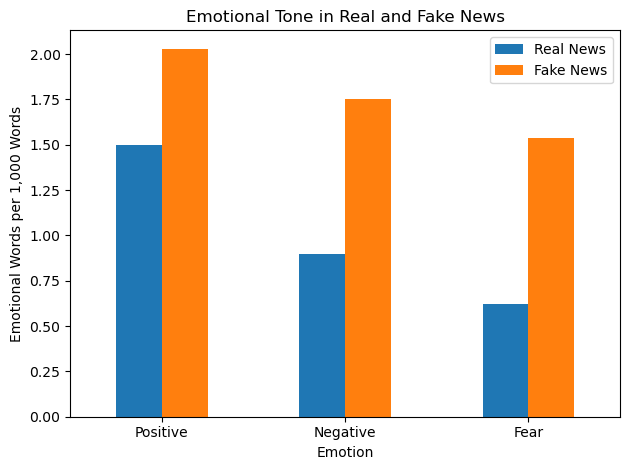

In [20]:
result.plot(x="Emotion", y=["Real News", "Fake News"], kind="bar")

plt.title("Emotional Tone in Real and Fake News")
plt.ylabel("Emotional Words per 1,000 Words")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()